In [731]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [732]:
from pandas.core.frame import DataFrame
df=pd.read_csv("/content/car details v4.csv")
pd.DataFrame(df)

,Make,Model,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
0,Honda,Amaze 1.2 VX i-VTEC,505000,2017,87150,Petrol,Manual,Pune,Grey,First,Corporate,1198 cc,87 bhp @ 6000 rpm,109 Nm @ 4500 rpm,FWD,3990.0,1680.0,1505.0,5.0,35.0
1,Maruti Suzuki,Swift DZire VDI,450000,2014,75000,Diesel,Manual,Ludhiana,White,Second,Individual,1248 cc,74 bhp @ 4000 rpm,190 Nm @ 2000 rpm,FWD,3995.0,1695.0,1555.0,5.0,42.0
2,Hyundai,i10 Magna 1.2 Kappa2,220000,2011,67000,Petrol,Manual,Lucknow,Maroon,First,Individual,1197 cc,79 bhp @ 6000 rpm,112.7619 Nm @ 4000 rpm,FWD,3585.0,1595.0,1550.0,5.0,35.0
3,Toyota,Glanza G,799000,2019,37500,Petrol,Manual,Mangalore,Red,First,Individual,1197 cc,82 bhp @ 6000 rpm,113 Nm @ 4200 rpm,FWD,3995.0,1745.0,1510.0,5.0,37.0
4,Toyota,Innova 2.4 VX 7 STR [2016-2020],1950000,2018,69000,Diesel,Manual,Mumbai,Grey,First,Individual,2393 cc,148 bhp @ 3400 rpm,343 Nm @ 1400 rpm,RWD,4735.0,1830.0,1795.0,7.0,55.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2054,Mahindra,XUV500 W8 [2015-2017],850000,2016,90300,Diesel,Manual,Surat,White,First,Individual,2179 cc,138 bhp @ 3750 rpm,330 Nm @ 1600 rpm,FWD,4585.0,1890.0,1785.0,7.0,70.0
2055,Hyundai,Eon D-Lite +,275000,2014,83000,Petrol,Manual,Ahmedabad,White,Second,Individual,814 cc,55 bhp @ 5500 rpm,75 Nm @ 4000 rpm,FWD,3495.0,1550.0,1500.0,5.0,32.0
2056,Ford,Figo Duratec Petrol ZXI 1.2,240000,2013,73000,Petrol,Manual,Thane,Silver,First,Individual,1196 cc,70 bhp @ 6250 rpm,102 Nm @ 4000 rpm,FWD,3795.0,1680.0,1427.0,5.0,45.0
2057,BMW,5-Series 520d Luxury Line [2017-2019],4290000,2018,60474,Diesel,Automatic,Coimbatore,White,First,Individual,1995 cc,188 bhp @ 4000 rpm,400 Nm @ 1750 rpm,RWD,4936.0,1868.0,1479.0,5.0,65.0


In [733]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2059 entries, 0 to 2058
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Make                2059 non-null   object 
 1   Model               2059 non-null   object 
 2   Price               2059 non-null   int64  
 3   Year                2059 non-null   int64  
 4   Kilometer           2059 non-null   int64  
 5   Fuel Type           2059 non-null   object 
 6   Transmission        2059 non-null   object 
 7   Location            2059 non-null   object 
 8   Color               2059 non-null   object 
 9   Owner               2059 non-null   object 
 10  Seller Type         2059 non-null   object 
 11  Engine              1979 non-null   object 
 12  Max Power           1979 non-null   object 
 13  Max Torque          1979 non-null   object 
 14  Drivetrain          1923 non-null   object 
 15  Length              1995 non-null   float64
 16  Width 

In [734]:
df.duplicated().sum()

np.int64(0)

In [735]:
numeric_text_cols = ["Price", "Year", "Kilometer", "Engine","Max Power", "Max Torque", "Length","Width", "Height", "Seating Capacity","Fuel Tank Capacity"]

for i in numeric_text_cols:
    if i in df.columns:
        cleaned = (df[i].astype("string").str.replace(",", "", regex=False).str.extract(r"([-+]?\d*\.?\d+)")[0])
        df[i] = pd.to_numeric(cleaned, errors="coerce")

In [736]:
round(df.describe())

,Price,Year,Kilometer,Engine,Max Power,Max Torque,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
count,2059.0,2059.0,2059.0,1979.0,1979.0,1979.0,1995.0,1995.0,1995.0,1995.0,1946.0
mean,1702992.0,2016.0,54225.0,1693.0,130.0,246.0,4281.0,1768.0,1592.0,5.0,52.0
std,2419881.0,3.0,57362.0,644.0,65.0,140.0,442.0,135.0,136.0,1.0,15.0
min,49000.0,1988.0,0.0,624.0,35.0,48.0,3099.0,1475.0,1165.0,2.0,15.0
25%,484999.0,2014.0,29000.0,1197.0,83.0,115.0,3985.0,1695.0,1485.0,5.0,41.0
50%,825000.0,2017.0,50000.0,1498.0,116.0,200.0,4370.0,1770.0,1545.0,5.0,50.0
75%,1925000.0,2019.0,72000.0,1995.0,171.0,350.0,4629.0,1832.0,1675.0,5.0,60.0
max,35000000.0,2022.0,2000000.0,6592.0,660.0,780.0,5569.0,2220.0,1995.0,8.0,105.0


In [737]:
num_cols = df.drop(columns=["Price"]).select_dtypes(include='number')
num_cols

,Year,Kilometer,Engine,Max Power,Max Torque,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
0,2017,87150,1198,87.0,109.0,3990.0,1680.0,1505.0,5.0,35.0
1,2014,75000,1248,74.0,190.0,3995.0,1695.0,1555.0,5.0,42.0
2,2011,67000,1197,79.0,112.7619,3585.0,1595.0,1550.0,5.0,35.0
3,2019,37500,1197,82.0,113.0,3995.0,1745.0,1510.0,5.0,37.0
4,2018,69000,2393,148.0,343.0,4735.0,1830.0,1795.0,7.0,55.0
...,...,...,...,...,...,...,...,...,...,...
2054,2016,90300,2179,138.0,330.0,4585.0,1890.0,1785.0,7.0,70.0
2055,2014,83000,814,55.0,75.0,3495.0,1550.0,1500.0,5.0,32.0
2056,2013,73000,1196,70.0,102.0,3795.0,1680.0,1427.0,5.0,45.0
2057,2018,60474,1995,188.0,400.0,4936.0,1868.0,1479.0,5.0,65.0


In [738]:
num_cols = df.drop(columns=["Price"]).select_dtypes(include='number')
num_cols

,Year,Kilometer,Engine,Max Power,Max Torque,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
0,2017,87150,1198,87.0,109.0,3990.0,1680.0,1505.0,5.0,35.0
1,2014,75000,1248,74.0,190.0,3995.0,1695.0,1555.0,5.0,42.0
2,2011,67000,1197,79.0,112.7619,3585.0,1595.0,1550.0,5.0,35.0
3,2019,37500,1197,82.0,113.0,3995.0,1745.0,1510.0,5.0,37.0
4,2018,69000,2393,148.0,343.0,4735.0,1830.0,1795.0,7.0,55.0
...,...,...,...,...,...,...,...,...,...,...
2054,2016,90300,2179,138.0,330.0,4585.0,1890.0,1785.0,7.0,70.0
2055,2014,83000,814,55.0,75.0,3495.0,1550.0,1500.0,5.0,32.0
2056,2013,73000,1196,70.0,102.0,3795.0,1680.0,1427.0,5.0,45.0
2057,2018,60474,1995,188.0,400.0,4936.0,1868.0,1479.0,5.0,65.0


In [739]:
cat_cols = df.select_dtypes(exclude='number').columns
cat_cols

Index(['Make', 'Model', 'Fuel Type', 'Transmission', 'Location', 'Color',
       'Owner', 'Seller Type', 'Drivetrain'],
      dtype='object')

In [740]:
for i in num_cols:
  df[i].fillna(df[i].median(),inplace=True)

for i in cat_cols:
  df[i].fillna(df[i].mode()[0],inplace=True)

/tmp/ipykernel_1045/2496797748.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[i].fillna(df[i].median(),inplace=True)
/tmp/ipykernel_1045/2496797748.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using '

In [741]:
df.isnull().sum()

,0
Make,0
Model,0
Price,0
Year,0
Kilometer,0
Fuel Type,0
Transmission,0
Location,0
Color,0
Owner,0


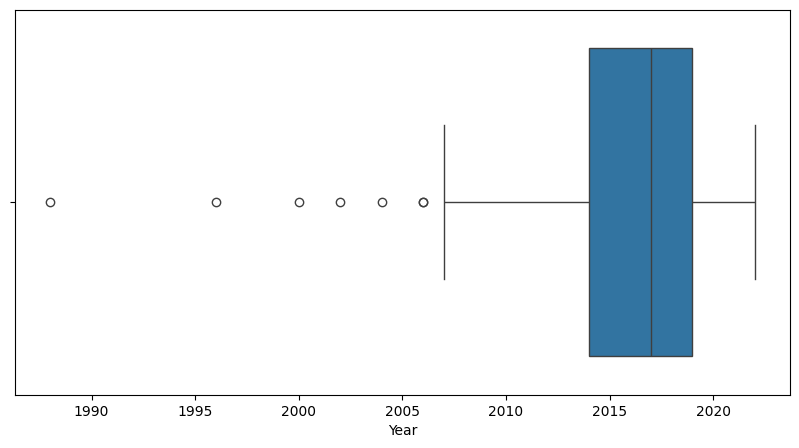

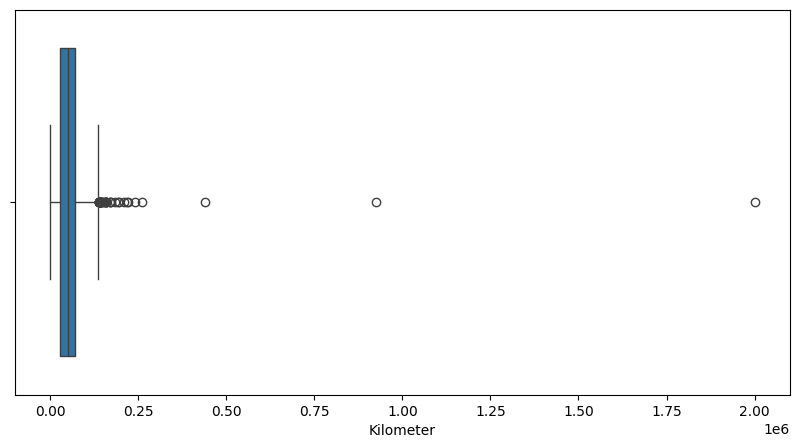

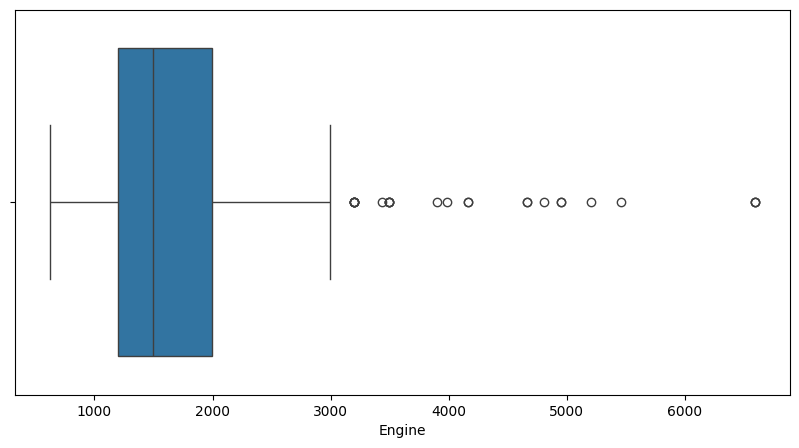

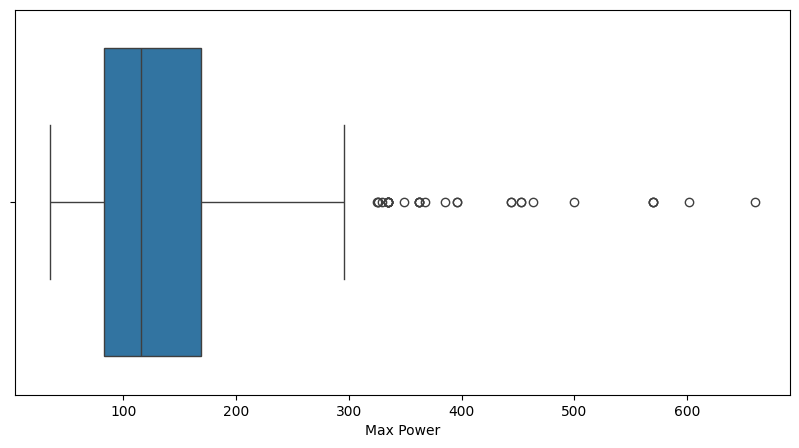

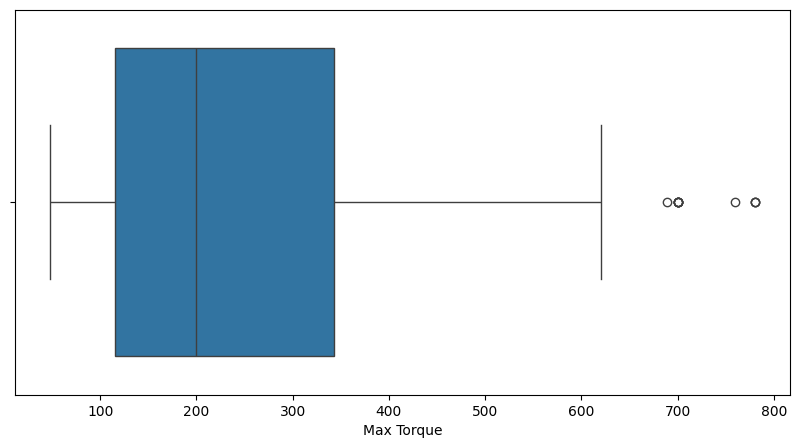

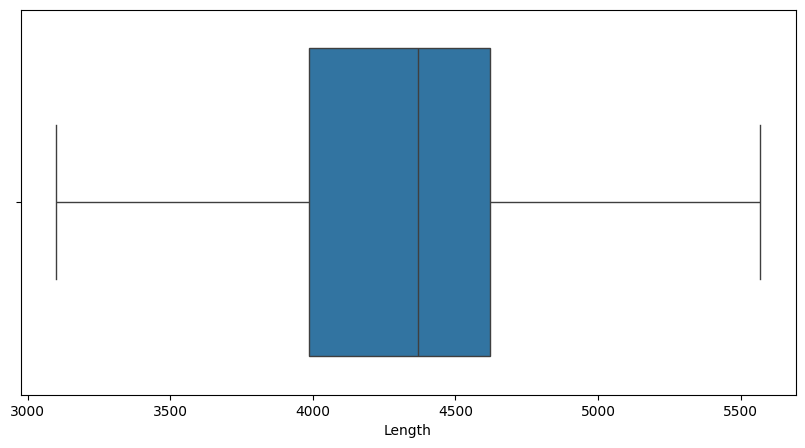

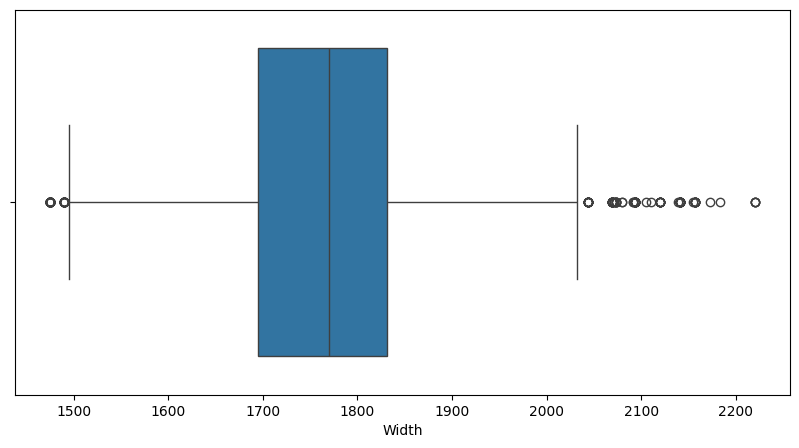

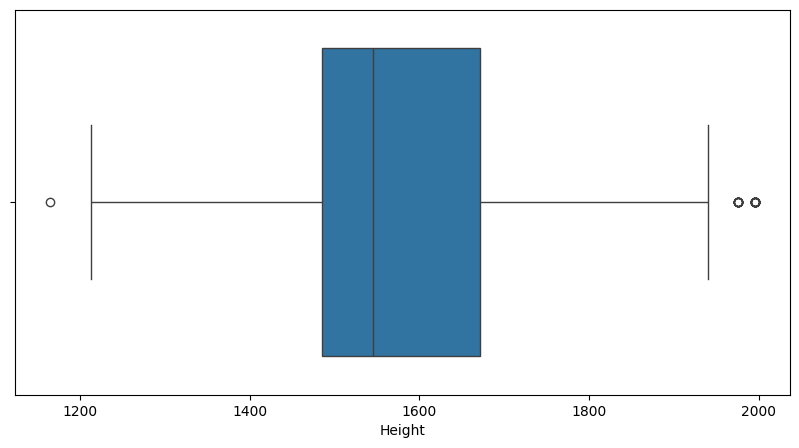

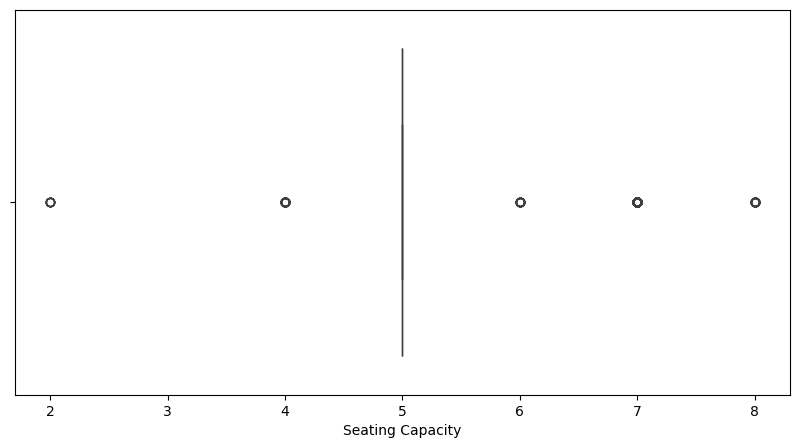

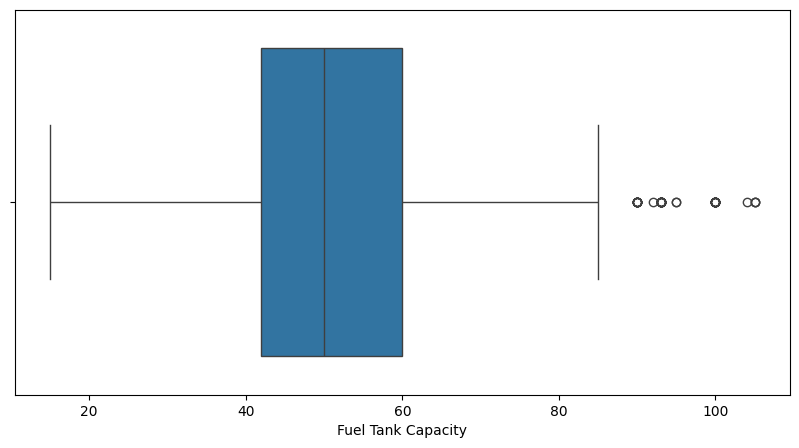

In [742]:
for i in num_cols:
  plt.figure(figsize=(10,5))
  sns.boxplot(data=df,x=i)
  plt.show()


In [743]:
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    print(col, "Remaining outliers:", count)

Year Remaining outliers: 7
Kilometer Remaining outliers: 36
Engine Remaining outliers: 25
Max Power Remaining outliers: 31
Max Torque Remaining outliers: 11
Length Remaining outliers: 0
Width Remaining outliers: 182
Height Remaining outliers: 31
Seating Capacity Remaining outliers: 380
Fuel Tank Capacity Remaining outliers: 50


In [744]:
def outlier_cap(df, cols):
  for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

  df[col] = df[col].clip(lower, upper)

  return df

df = outlier_cap(df, num_cols)

In [745]:
df[num_cols.columns].skew()

,0
Year,-0.840685
Kilometer,20.980719
Engine,1.815411
Max Power,2.13171
Max Torque,0.929859
Length,-0.040649
Width,0.311823
Height,0.877625
Seating Capacity,1.515381
Fuel Tank Capacity,0.690685


In [746]:
df['Kilometer'] = np.log1p(df['Kilometer'])
df['Max Power'] = np.log1p(df['Max Power'])
df['Engine'] = np.cbrt(df['Engine'])
df['Max Torque'] = np.cbrt(df['Max Torque'])
df['Height'] = np.cbrt(df['Height'])
df['Seating Capacity'] = np.cbrt(df['Seating Capacity'])
df['Fuel Tank Capacity'] = np.cbrt(df['Fuel Tank Capacity'])

In [747]:
df[num_cols.columns].skew()

,0
Year,-0.840685
Kilometer,-3.030742
Engine,0.78367
Max Power,0.371283
Max Torque,0.28847
Length,-0.040649
Width,0.311823
Height,0.765342
Seating Capacity,0.890746
Fuel Tank Capacity,0.340388


In [748]:
X = df.drop('Price',axis=1)
y = df['Price']

In [749]:
df.head(3)

,Make,Model,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
0,Honda,Amaze 1.2 VX i-VTEC,505000,2017,11.375398,Petrol,Manual,Pune,Grey,First,Corporate,10.620679,4.477337,4.776856,FWD,3990.0,1680.0,11.459847,1.709976,3.271066
1,Maruti Suzuki,Swift DZire VDI,450000,2014,11.225257,Diesel,Manual,Ludhiana,White,Second,Individual,10.766425,4.317488,5.748897,FWD,3995.0,1695.0,11.585376,1.709976,3.476027
2,Hyundai,i10 Magna 1.2 Kappa2,220000,2011,11.112463,Petrol,Manual,Lucknow,Maroon,First,Individual,10.617723,4.382027,4.83119,FWD,3585.0,1595.0,11.572945,1.709976,3.271066


In [750]:
cat_cols

Index(['Make', 'Model', 'Fuel Type', 'Transmission', 'Location', 'Color',
       'Owner', 'Seller Type', 'Drivetrain'],
      dtype='object')

In [751]:
X_enc = pd.get_dummies(X,columns=cat_cols,drop_first=True,dtype='int')
X_enc.head(3)

,Year,Kilometer,Engine,Max Power,Max Torque,Length,Width,Height,Seating Capacity,Fuel Tank Capacity,...,Color_Yellow,Owner_First,Owner_Fourth,Owner_Second,Owner_Third,Owner_UnRegistered Car,Seller Type_Corporate,Seller Type_Individual,Drivetrain_FWD,Drivetrain_RWD
0,2017,11.375398,10.620679,4.477337,4.776856,3990.0,1680.0,11.459847,1.709976,3.271066,...,0,1,0,0,0,0,1,0,1,0
1,2014,11.225257,10.766425,4.317488,5.748897,3995.0,1695.0,11.585376,1.709976,3.476027,...,0,0,0,1,0,0,0,1,1,0
2,2011,11.112463,10.617723,4.382027,4.83119,3585.0,1595.0,11.572945,1.709976,3.271066,...,0,1,0,0,0,0,0,1,1,0


SCALING

In [752]:
from sklearn.preprocessing import StandardScaler

# Identify original numerical columns before encoding
num_cols = X.select_dtypes(include='number').columns

# Create one dataset containing encoded values
X_scaled = X_enc.copy()

# Scale only original numerical columns
scaler = StandardScaler()
X_scaled[num_cols] = scaler.fit_transform(X_enc[num_cols])

# Display the final dataset
X_scaled.head()


,Year,Kilometer,Engine,Max Power,Max Torque,Length,Width,Height,Seating Capacity,Fuel Tank Capacity,...,Color_Yellow,Owner_First,Owner_Fourth,Owner_Second,Owner_Third,Owner_UnRegistered Car,Seller Type_Corporate,Seller Type_Individual,Drivetrain_FWD,Drivetrain_RWD
0,0.170858,0.828588,-0.825128,-0.678565,-1.097522,-0.673941,-0.661496,-0.633142,-0.342477,-1.284243,...,0,1,0,0,0,0,1,0,1,0
1,-0.721270,0.663794,-0.717715,-1.048978,-0.249759,-0.662465,-0.548810,-0.242739,-0.342477,-0.663901,...,0,0,0,1,0,0,0,1,1,0
2,-1.613398,0.539993,-0.827306,-0.899425,-1.050135,-1.603494,-1.300046,-0.281399,-0.342477,-1.284243,...,0,1,0,0,0,0,0,1,1,0
3,0.765609,-0.096983,-0.827306,-0.814117,-1.047171,-0.662465,-0.173193,-0.593716,-0.342477,-1.099147,...,0,1,0,0,0,0,0,1,1,0
4,0.468234,0.572277,1.205221,0.541733,0.841386,1.035978,0.465357,1.523018,2.053834,0.325587,...,0,1,0,0,0,0,0,1,0,1


MODEL DEVOLPMENT

In [753]:
from sklearn.model_selection import train_test_split
y = df['Price']
X =  X_scaled
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)



In [754]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1647, 1201), (412, 1201), (1647,), (412,))

In [755]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Create the model
lr = LinearRegression()
lr

LinearRegression()

In [756]:
# Train the model
lr.fit(X_train, y_train)

# Predict
y_pred_lr = lr.predict(X_test)

# Evaluate
print("Linear Regression")
print("MSE:", mean_squared_error(y_test, y_pred_lr))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_lr)))
print("MAE:", mean_absolute_error(y_test, y_pred_lr))
print("R2 Score:", r2_score(y_test, y_pred_lr)*100)

Linear Regression
MSE: 14236821200776.928
RMSE: 3773171.239259746
MAE: 1584878.6343207965
R2 Score: -103.78251000034683


In [764]:
sample_car = pd.DataFrame([{
    "Make": "BMW",
    "Model": "3 Series",
    "Kilometer": 35000,
    "Fuel Type": "Petrol",
    "Transmission": "Automatic",
    "Location": "Mumbai",
    "Color": "Black",
    "Owner": "First",
    "Seller Type": "Dealer",
    "Engine": 1998,
    "Max Power": 190,
    "Max Torque": 300,
    "Drivetrain": "RWD",
    "Length": 4709,
    "Width": 1827,
    "Height": 1442,
    "Seating Capacity": 5,
    "Fuel Tank Capacity": 59,
    "Car Age": 6
}])

# Apply the same encoding columns used in training
sample_car = pd.get_dummies(sample_car, dtype=int)
sample_car = sample_car.reindex(
    columns=X_train.columns,
    fill_value=0
)


# Train the model
lr.fit(X_train, y_train)

# Predict
y_ = lr.predict(X_test)

# Predict price
# Predict
y_

array([ 1.28970475e+07,  8.24909841e+05, -2.61173250e+06,  1.20740672e+06,
        6.56871194e+05,  1.30935729e+04, -1.22261503e+06,  4.67087597e+05,
        1.34038193e+07,  2.57799535e+06,  4.35233500e+05,  3.94614798e+05,
        1.49949064e+06,  3.03732283e+06,  4.85985860e+04,  2.14047543e+05,
        1.22272937e+06,  1.07969755e+06,  1.90906230e+06,  1.79107889e+06,
        5.53078118e+06,  2.71782587e+05,  8.87572236e+05,  7.68895807e+05,
        5.98559952e+05,  9.04742857e+05,  8.57000001e+05,  1.03304558e+06,
        2.36640966e+06,  1.00261395e+06,  5.30448686e+05,  5.35183563e+06,
        1.54409992e+06,  6.81095162e+05,  6.21411839e+05,  2.09677516e+06,
        3.15199347e+05,  7.88722004e+06,  1.21557038e+06,  1.35002278e+07,
        3.29645996e+06,  1.04140375e+06,  4.15444526e+06,  2.26519105e+05,
       -1.84954411e+06, -8.49322896e+06,  2.63359896e+06,  6.72558621e+05,
        6.01365096e+05,  3.08419821e+06,  1.05004818e+06,  6.61090319e+06,
        2.64255517e+05,  